# Лабораторная 7. Автоэнкодеры

**Задание.** Реализовать автоэнкодеры: а) автоэнкодер с полносвязными слоями;
б) вариационный автоэнкодер.

Для обеих моделей, используя выборки MNIST и FashionMNIST:

1) реализовать различные варианты зашумления и исследовать, как зависит качество
нормализации изображения (очистки от шума): а) от типа зашумления (равномерный
шум, нормальный шум, локальная порча изображений); б) от размерности пространства
скрытых признаков; в) от количества и ширины слоёв кодера и декодера; а также от
гиперпараметров: г) количества эпох; д) коэффициента обучения;

2) оценить качество изображений, восстановленных из чистых и зашумлённых
изображений;

3) оценить возможность генерирования новых изображений из случайных точек в
латентном пространстве (пространстве скрытых признаков).

## 1. Теория

### Данные

MNIST и FashionMNIST: изображения $28 \times 28$ в градациях серого, 10 классов.
Из обучающей части каждой выборки берутся 8000 изображений для обучения и 1000
отложенных для сравнения гиперпараметров, из тестовой части 1000 изображений для
итоговой оценки. Яркости делятся на 255, изображение разворачивается в вектор
длины 784.

### Автоэнкодер

Автоэнкодер состоит из кодера $f$ и декодера $g$ и обучается восстанавливать
собственный вход:

$$z = f(x), \qquad \hat x = g(z), \qquad L = \lVert x - \hat x\rVert^2 .$$

Размерность $z$ меньше размерности $x$, поэтому сеть вынуждена сжать изображение
до $d$ чисел так, чтобы по ним его можно было восстановить.

### Очистка от шума

Шумоподавляющий автоэнкодер обучается на парах "зашумлённое изображение на
входе, чистое на выходе":

$$L = \lVert x - g(f(\tilde x))\rVert^2, \qquad \tilde x = \text{шум}(x).$$

Виды зашумления: равномерный шум (добавка $\mathrm{U}[-\ell, \ell]$ к каждому
пикселю), нормальный шум (добавка $\mathrm{N}(0, \ell^2)$), после добавки
значения обрезаются до $[0, 1]$; локальная порча: два квадратных пятна случайного
положения со стороной $28\ell$, но не меньше 4 пикселей, заполненные случайными
значениями.

### Вариационный автоэнкодер

Кодер выдаёт не точку, а параметры распределения $\mu(x)$ и $\log\sigma^2(x)$;
код берётся как $z = \mu + \sigma\varepsilon$ при
$\varepsilon \sim \mathcal{N}(0, I)$ (репараметризация, благодаря которой
градиент проходит через выборку). Функция потерь

$$L = \underbrace{\lVert x - \hat x\rVert^2}_{\text{восстановление}}
    + \beta\underbrace{\left(-\tfrac12\sum_{j}\bigl(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\bigr)\right)}_{\text{KL-дивергенция}} .$$

Второе слагаемое стягивает распределение кодов к $\mathcal{N}(0, I)$, поэтому
точка, взятая из $\mathcal{N}(0, I)$, декодируется в правдоподобное изображение.
Здесь $\beta = 1$. При оценке восстановления берётся $z = \mu$.

### Меры качества

$$\mathrm{MSE} = \frac{1}{n}\sum_k (x_k - \hat x_k)^2 .$$

SSIM (structural similarity) сравнивает локальные яркость, контраст и структуру
и лучше согласуется со зрительной оценкой; значение 1 означает совпадение.

### Что перебирается

| Параметр | Значения | Базовое значение |
|---|---|---|
| тип шума | равномерный, нормальный, пятна | нормальный |
| уровень шума | $0.2$, $0.4$ | $0.3$ |
| размерность латента | 2, 4, 8, 16, 32, 64 | 32 |
| слои кодера | $(128)$, $(256)$, $(512, 256)$, $(512, 256, 128)$ | $(256)$ |
| число эпох | 10, 20, 40 | 20 |
| коэффициент обучения | $3\cdot10^{-4}$, $10^{-3}$, $3\cdot10^{-3}$ | $10^{-3}$ |

Исследование проводится для обеих моделей и обеих выборок. На каждом этапе
меняется один параметр, остальные берутся базовыми. Число эпох и коэффициент
обучения перебираются вместе: модель обучается 40 эпох, качество замеряется
после 10, 20 и 40 эпох. Качество считается на отложенных изображениях: MSE и
SSIM восстановления чистого изображения по зашумлённому. Для итоговых моделей
по каждой паре "выборка, модель" берутся лучшие по MSE значения размерности
латента, слоёв кодера, числа эпох и коэффициента обучения. Оптимизатор Adam,
батч 128.

## 2. Данные и модели шума

In [1]:
import os
import struct
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity
from sklearn.decomposition import PCA

torch.manual_seed(20260905)
RNG = np.random.default_rng(20260905)
plt.rcParams['figure.dpi'] = 110

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'torch {torch.__version__}, устройство: {DEVICE}')

torch 2.14.1+cu130, устройство: cpu


In [2]:
def read_idx(path):
    with open(path, 'rb') as f:
        magic, = struct.unpack('>I', f.read(4))
        dims = struct.unpack('>' + 'I' * (magic & 0xff), f.read(4 * (magic & 0xff)))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(dims)


def find_dir(name, env):
    for c in [os.environ.get(env), f'../data/{name}/raw', f'data/{name}/raw',
              '../../bachelor/Perceptron/data_generation/MNIST/raw' if name == 'MNIST' else None]:
        if c and Path(c, 'train-images-idx3-ubyte').exists():
            return Path(c)
    raise FileNotFoundError(name)


def load(name, env, n_train, n_val, n_test, rng):
    """Обучающая и отложенная части из обучающей выборки, тестовая из тестовой."""
    D = find_dir(name, env)
    Xtr = read_idx(D / 'train-images-idx3-ubyte')
    Xte = read_idx(D / 't10k-images-idx3-ubyte')
    yte = read_idx(D / 't10k-labels-idx1-ubyte')
    perm = rng.permutation(len(Xtr))
    itr, ival = perm[:n_train], perm[n_train:n_train + n_val]  # части не пересекаются
    ite = rng.choice(len(Xte), n_test, replace=False)
    return (Xtr[itr].astype(np.float32) / 255.0, Xtr[ival].astype(np.float32) / 255.0,
            Xte[ite].astype(np.float32) / 255.0, yte[ite])


DATA = {
    'MNIST': load('MNIST', 'MNIST_DIR', 8000, 1000, 1000, np.random.default_rng(20260905)),
    'FashionMNIST': load('FashionMNIST', 'FASHION_DIR', 8000, 1000, 1000,
                         np.random.default_rng(20260905)),
}
for k, (a, b, c, _) in DATA.items():
    print(f'{k}: обучающая {a.shape}, отложенная {b.shape}, тестовая {c.shape}')

MNIST: обучающая (8000, 28, 28), отложенная (1000, 28, 28), тестовая (1000, 28, 28)
FashionMNIST: обучающая (8000, 28, 28), отложенная (1000, 28, 28), тестовая (1000, 28, 28)


In [3]:
def noise_uniform(X, level, rng):
    """Равномерный шум: добавка U[-level, level] к каждому пикселю."""
    return np.clip(X + rng.uniform(-level, level, X.shape), 0, 1).astype(np.float32)


def noise_normal(X, level, rng):
    """Нормальный шум с sigma = level."""
    return np.clip(X + rng.normal(0, level, X.shape), 0, 1).astype(np.float32)


def noise_blot(X, level, rng):
    """Локальная порча: квадратные пятна случайного положения."""
    X = X.copy()
    size = max(4, int(round(28 * level)))
    n_blots = 2
    for i in range(len(X)):
        for _ in range(n_blots):
            r0 = rng.integers(0, 28 - size + 1)
            c0 = rng.integers(0, 28 - size + 1)
            X[i, r0:r0 + size, c0:c0 + size] = rng.random((size, size))
    return X.astype(np.float32)


NOISES = {'равномерный': noise_uniform, 'нормальный': noise_normal,
          'пятна': noise_blot}

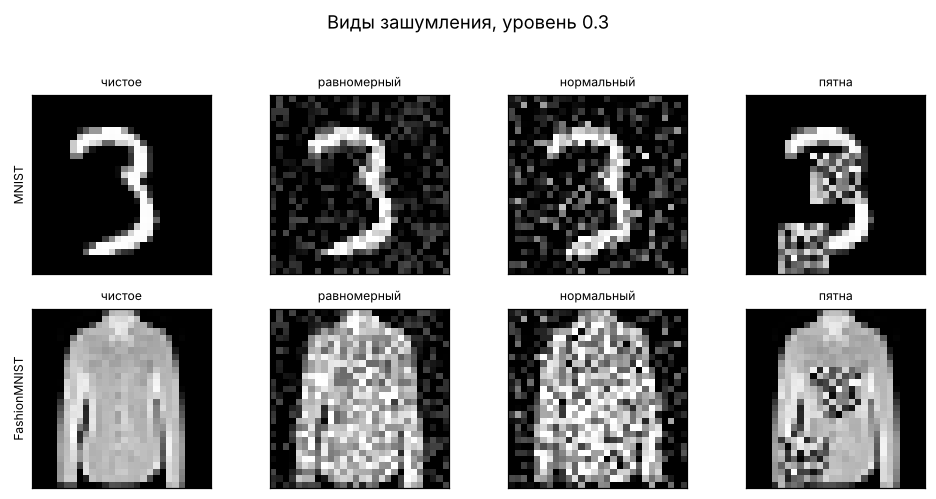

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(9, 4.4))
for row, ds in enumerate(['MNIST', 'FashionMNIST']):
    X = DATA[ds][1]
    axes[row, 0].imshow(X[0], cmap='gray'); axes[row, 0].set_title('чистое', fontsize=8)
    for col, (name, f) in enumerate(NOISES.items(), start=1):
        axes[row, col].imshow(f(X[:1], 0.3, np.random.default_rng(1))[0], cmap='gray')
        axes[row, col].set_title(name, fontsize=8)
    for ax in axes[row]:
        ax.set_xticks([]); ax.set_yticks([])
    axes[row, 0].set_ylabel(ds, fontsize=8)
fig.suptitle('Виды зашумления, уровень 0.3', y=1.02)
plt.tight_layout()
plt.show()

## 3. Автоэнкодер и вариационный автоэнкодер

In [5]:
def dense_stack(dims):
    """Полносвязные слои с ReLU между ними по размерам dims."""
    layers = []
    for a, b in zip(dims[:-1], dims[1:]):
        layers += [nn.Linear(a, b), nn.ReLU()]
    return layers


class AE(nn.Module):
    """Автоэнкодер с полносвязными слоями."""

    def __init__(self, latent=16, hidden=(256,)):
        super().__init__()
        self.latent = latent
        hidden = list(hidden)
        # кодер сужает 784 до latent, декодер разворачивает обратно теми же ширинами
        self.encoder = nn.Sequential(*dense_stack([784] + hidden),
                                     nn.Linear(hidden[-1], latent))
        self.decoder = nn.Sequential(*dense_stack([latent] + hidden[::-1]),
                                     nn.Linear(hidden[0], 784), nn.Sigmoid())

    def forward(self, x):
        return self.decoder(self.encoder(x)), None

    def sample(self, n):
        """Декодирование n случайных точек латентного пространства."""
        device = next(self.parameters()).device  # где лежат веса, там и считаем
        return self.decoder(torch.randn(n, self.latent, device=device))


class VAE(nn.Module):
    """Вариационный автоэнкодер."""

    def __init__(self, latent=16, hidden=(256,)):
        super().__init__()
        self.latent = latent
        hidden = list(hidden)
        self.encoder = nn.Sequential(*dense_stack([784] + hidden))
        self.mu = nn.Linear(hidden[-1], latent)          # среднее распределения кодов
        self.logvar = nn.Linear(hidden[-1], latent)      # логарифм дисперсии
        self.decoder = nn.Sequential(*dense_stack([latent] + hidden[::-1]),
                                     nn.Linear(hidden[0], 784), nn.Sigmoid())

    def forward(self, x):
        h = self.encoder(x)
        mu, logvar = self.mu(h), self.logvar(h)
        if not self.training:  # при оценке код берётся равным среднему
            return self.decoder(mu), (mu, logvar)
        # репараметризация: z = mu + sigma * eps, случайность вынесена в eps
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decoder(z), (mu, logvar)

    def sample(self, n):
        device = next(self.parameters()).device
        return self.decoder(torch.randn(n, self.latent, device=device))

In [6]:
def train_ae(model, Xn, Xc, epochs, lr, batch=128, beta=1.0, seed=0, after_epoch=None):
    """Xn это вход (возможно зашумлённый), Xc это цель (чистое изображение).
    after_epoch, если задана, вызывается с номером эпохи после каждой эпохи."""
    torch.manual_seed(seed)
    model.to(DEVICE)  # веса переносятся на видеокарту, если она есть
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    xn = torch.tensor(Xn.reshape(len(Xn), -1)).to(DEVICE)  # каждое изображение в строку
    xc = torch.tensor(Xc.reshape(len(Xc), -1)).to(DEVICE)
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(xn), device=DEVICE)  # новый порядок объектов
        for s in range(0, len(xn), batch):
            b = perm[s:s + batch]
            out, extra = model(xn[b])
            loss = ((out - xc[b]) ** 2).sum(1).mean()  # квадрат нормы x - x_hat, среднее по батчу
            if extra is not None:  # у VAE добавляется KL-слагаемое
                mu, logvar = extra
                kl = -0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(1).mean()
                loss = loss + beta * kl
            opt.zero_grad()  # обнуление градиентов прошлого шага
            loss.backward()  # градиенты функции потерь по весам
            opt.step()  # шаг оптимизатора
        if after_epoch is not None:
            after_epoch(epoch)


def reconstruct(model, X):
    """Прогон изображений через сеть и обратно в форму (N, 28, 28)."""
    model.eval()
    with torch.no_grad():  # при оценке градиенты не нужны
        out, _ = model(torch.tensor(X.reshape(len(X), -1)).to(DEVICE))
    return out.cpu().numpy().reshape(-1, 28, 28)  # .cpu() забирает результат с видеокарты


def quality(ref, rec):
    """MSE по пикселям и средний SSIM по изображениям."""
    mse = float(np.mean((ref - rec) ** 2))
    ssim = float(np.mean([structural_similarity(a, b, data_range=1.0)
                          for a, b in zip(ref, rec)]))
    return mse, ssim

In [7]:
MODELS = {'AE': AE, 'VAE': VAE}
DATASETS = ['MNIST', 'FashionMNIST']
BASE = dict(noise='нормальный', level=0.3, latent=32, hidden=(256,), epochs=20, lr=1e-3)


def experiment(stage, ds, model_name, **changes):
    """Обучение модели с базовыми параметрами, часть которых заменена, и замер на отложенной."""
    cfg = {**BASE, **changes}  # параметры BASE, часть из них заменена
    Xtr, Xval, _, _ = DATA[ds]
    noise = NOISES[cfg['noise']]
    Xtr_n = noise(Xtr, cfg['level'], np.random.default_rng(20260905))
    Xval_n = noise(Xval, cfg['level'], np.random.default_rng(1))
    torch.manual_seed(20260905)
    model = MODELS[model_name](latent=cfg['latent'], hidden=cfg['hidden'])
    train_ae(model, Xtr_n, Xtr, epochs=cfg['epochs'], lr=cfg['lr'])
    mse_n, ssim_n = quality(Xval, reconstruct(model, Xval_n))
    mse_c, ssim_c = quality(Xval, reconstruct(model, Xval))
    row = dict(stage=stage, dataset=ds, model=model_name, **cfg,
               mse_noisy=mse_n, ssim_noisy=ssim_n, mse_clean=mse_c, ssim_clean=ssim_c,
               params=sum(p.numel() for p in model.parameters()))
    return row, model


def show(df, index, value):
    """Таблица: строки - значения параметра, столбцы - выборка и модель."""
    piv = df.pivot_table(index=index, columns=['dataset', 'model'], values=value)
    piv = piv[[(d, m) for d in DATASETS for m in MODELS]]
    print((piv.astype(int) if value == 'params' else piv.round(4)).to_string())

## 4. Тип и уровень зашумления

In [8]:
rows, denoisers = [], {}
for ds in DATASETS:
    Xval = DATA[ds][1]
    for model_name in MODELS:
        for nname in NOISES:
            for level in [0.2, 0.4]:
                row, model = experiment('шум', ds, model_name, noise=nname, level=level)
                # качество самого зашумлённого входа, с ним сравнивается выход сети
                Xval_n = NOISES[nname](Xval, level, np.random.default_rng(1))
                row['mse_input'], row['ssim_input'] = quality(Xval, Xval_n)
                rows.append(row)
                if model_name == 'AE' and level == 0.4:
                    denoisers[(ds, nname)] = model
noi = pd.DataFrame(rows)
noi['выигрыш SSIM'] = noi.ssim_noisy - noi.ssim_input
print(noi[['dataset', 'model', 'noise', 'level', 'ssim_input', 'ssim_noisy', 'выигрыш SSIM',
           'mse_input', 'mse_noisy']].round(4).to_string(index=False))

     dataset model       noise  level  ssim_input  ssim_noisy  выигрыш SSIM  mse_input  mse_noisy
       MNIST    AE равномерный    0.2      0.6761      0.8360        0.1599     0.0073     0.0128
       MNIST    AE равномерный    0.4      0.5774      0.8122        0.2348     0.0284     0.0149
       MNIST    AE  нормальный    0.2      0.6095      0.8189        0.2094     0.0211     0.0141
       MNIST    AE  нормальный    0.4      0.4436      0.7594        0.3158     0.0794     0.0195
       MNIST    AE       пятна    0.2      0.8094      0.7599       -0.0495     0.0274     0.0187
       MNIST    AE       пятна    0.4      0.5350      0.5810        0.0460     0.0824     0.0356
       MNIST   VAE равномерный    0.2      0.6761      0.6268       -0.0492     0.0073     0.0248
       MNIST   VAE равномерный    0.4      0.5774      0.6041        0.0266     0.0284     0.0275
       MNIST   VAE  нормальный    0.2      0.6095      0.6163        0.0068     0.0211     0.0262
       MNIST   VAE  

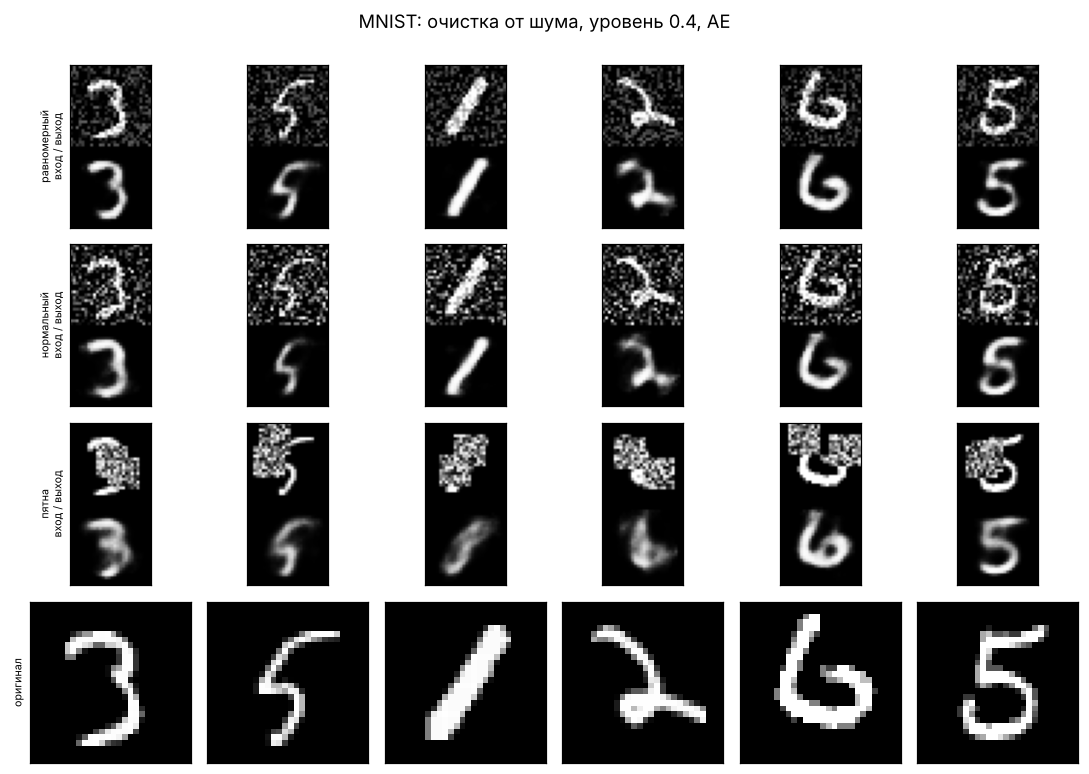

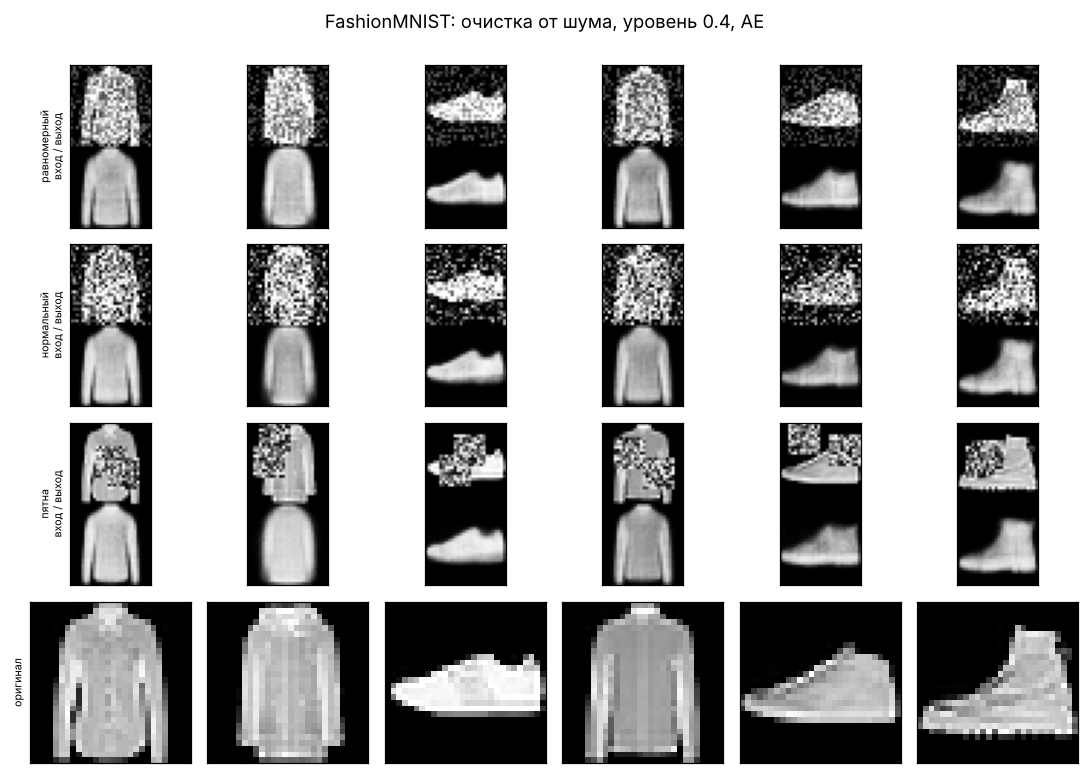

In [9]:
for ds in DATASETS:
    Xval = DATA[ds][1]
    fig, axes = plt.subplots(4, 6, figsize=(10, 7))
    for row, nname in enumerate(NOISES):
        Xval_n = NOISES[nname](Xval, 0.4, np.random.default_rng(1))
        rec = reconstruct(denoisers[(ds, nname)], Xval_n)
        for col in range(6):
            # vstack ставит вход над выходом, получается две строки в одной картинке
            axes[row, col].imshow(np.vstack([Xval_n[col], rec[col]]), cmap='gray')
            axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
        axes[row, 0].set_ylabel(f'{nname}\nвход / выход', fontsize=7)
    for col in range(6):
        axes[3, col].imshow(Xval[col], cmap='gray')
        axes[3, col].set_xticks([]); axes[3, col].set_yticks([])
    axes[3, 0].set_ylabel('оригинал', fontsize=7)
    fig.suptitle(f'{ds}: очистка от шума, уровень 0.4, AE', y=1.0)
    plt.tight_layout()
    plt.show()

## 5. Размерность латентного пространства

In [10]:
lat = pd.DataFrame([experiment('латент', ds, m, latent=d)[0]
                    for ds in DATASETS for m in MODELS for d in [2, 4, 8, 16, 32, 64]])
print('MSE восстановления по зашумлённому:')
show(lat, 'latent', 'mse_noisy')
print('\nSSIM восстановления по зашумлённому:')
show(lat, 'latent', 'ssim_noisy')

MSE восстановления по зашумлённому:
dataset   MNIST         FashionMNIST        
model        AE     VAE           AE     VAE
latent                                      
2        0.0504  0.0489       0.0346  0.0339
4        0.0367  0.0386       0.0232  0.0247
8        0.0271  0.0288       0.0194  0.0231
16       0.0204  0.0282       0.0179  0.0243
32       0.0164  0.0286       0.0175  0.0260
64       0.0154  0.0313       0.0173  0.0286

SSIM восстановления по зашумлённому:
dataset   MNIST         FashionMNIST        
model        AE     VAE           AE     VAE
latent                                      
2        0.4053  0.3940       0.4524  0.4578
4        0.5659  0.5110       0.5816  0.5366
8        0.6858  0.6213       0.6217  0.5569
16       0.7534  0.6084       0.6384  0.5327
32       0.7914  0.5915       0.6444  0.5228
64       0.8037  0.5296       0.6475  0.4957


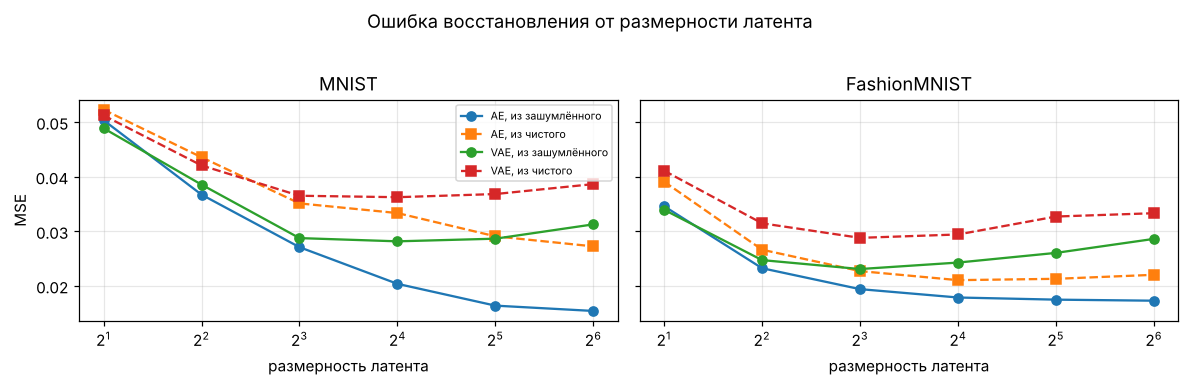

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, ds in zip(axes, DATASETS):
    for m in MODELS:
        s = lat[(lat.dataset == ds) & (lat.model == m)].sort_values('latent')
        ax.plot(s.latent, s.mse_noisy, marker='o', label=f'{m}, из зашумлённого')
        ax.plot(s.latent, s.mse_clean, marker='s', ls='--', label=f'{m}, из чистого')
    ax.set_xscale('log', base=2); ax.set_xlabel('размерность латента')
    ax.set_title(ds); ax.grid(alpha=0.3)
axes[0].set_ylabel('MSE'); axes[0].legend(fontsize=7)
fig.suptitle('Ошибка восстановления от размерности латента', y=1.02)
plt.tight_layout()
plt.show()

## 6. Число и ширина слоёв кодера и декодера

In [12]:
HIDDENS = [(128,), (256,), (512, 256), (512, 256, 128)]
arch = pd.DataFrame([experiment('слои', ds, m, hidden=h)[0]
                     for ds in DATASETS for m in MODELS for h in HIDDENS])
arch['hidden'] = arch['hidden'].astype(str)
print('MSE восстановления по зашумлённому:')
show(arch, 'hidden', 'mse_noisy')
print('\nSSIM восстановления по зашумлённому:')
show(arch, 'hidden', 'ssim_noisy')
print('\nчисло параметров:')
show(arch, 'hidden', 'params')

MSE восстановления по зашумлённому:
dataset           MNIST         FashionMNIST        
model                AE     VAE           AE     VAE
hidden                                              
(128,)           0.0209  0.0317       0.0193  0.0269
(256,)           0.0164  0.0286       0.0175  0.0260
(512, 256)       0.0201  0.0377       0.0191  0.0264
(512, 256, 128)  0.0271  0.0462       0.0215  0.0331

SSIM восстановления по зашумлённому:
dataset           MNIST         FashionMNIST        
model                AE     VAE           AE     VAE
hidden                                              
(128,)           0.7402  0.5463       0.6167  0.5035
(256,)           0.7914  0.5915       0.6444  0.5228
(512, 256)       0.7712  0.5491       0.6291  0.5578
(512, 256, 128)  0.7015  0.4402       0.5996  0.4775

число параметров:
dataset            MNIST          FashionMNIST         
model                 AE      VAE           AE      VAE
hidden                                               

## 7. Число эпох и коэффициент обучения

In [13]:
rows = []
for ds in DATASETS:
    Xtr, Xval, _, _ = DATA[ds]
    Xtr_n = noise_normal(Xtr, BASE['level'], np.random.default_rng(20260905))
    Xval_n = noise_normal(Xval, BASE['level'], np.random.default_rng(1))
    for m in MODELS:
        for lr in [3e-4, 1e-3, 3e-3]:
            torch.manual_seed(20260905)
            model = MODELS[m](latent=BASE['latent'], hidden=BASE['hidden'])

            def measure(epoch):
                if epoch in (10, 20, 40):
                    mse, ssim = quality(Xval, reconstruct(model, Xval_n))
                    rows.append(dict(stage='обучение', dataset=ds, model=m, **{**BASE, 'epochs': epoch, 'lr': lr},
                                     mse_noisy=mse, ssim_noisy=ssim))

            train_ae(model, Xtr_n, Xtr, epochs=40, lr=lr, after_epoch=measure)
sched = pd.DataFrame(rows)
for ds in DATASETS:
    for m in MODELS:
        s = sched[(sched.dataset == ds) & (sched.model == m)]
        print(f'{ds}, {m}: MSE восстановления по зашумлённому')
        print(s.pivot_table(index='lr', columns='epochs', values='mse_noisy').round(4).to_string())
        print()

MNIST, AE: MSE восстановления по зашумлённому
epochs      10      20      40
lr                            
0.0003  0.0326  0.0243  0.0179
0.0010  0.0213  0.0164  0.0140
0.0030  0.0167  0.0143  0.0142

MNIST, VAE: MSE восстановления по зашумлённому
epochs      10      20      40
lr                            
0.0003  0.0454  0.0357  0.0295
0.0010  0.0357  0.0286  0.0250
0.0030  0.0322  0.0280  0.0257

FashionMNIST, AE: MSE восстановления по зашумлённому
epochs      10      20      40
lr                            
0.0003  0.0261  0.0222  0.0187
0.0010  0.0204  0.0175  0.0155
0.0030  0.0172  0.0153  0.0148

FashionMNIST, VAE: MSE восстановления по зашумлённому
epochs      10      20      40
lr                            
0.0003  0.0345  0.0299  0.0260
0.0010  0.0319  0.0260  0.0236
0.0030  0.0277  0.0244  0.0229



## 8. Итоговые модели: восстановление и генерация

In [14]:
best = {}
for ds in DATASETS:
    for m in MODELS:
        pick = lambda df: df[(df.dataset == ds) & (df.model == m)].sort_values('mse_noisy').iloc[0]
        s = pick(sched)
        best[(ds, m)] = dict(latent=int(pick(lat)['latent']),
                             hidden=dict((str(h), h) for h in HIDDENS)[pick(arch)['hidden']],
                             epochs=int(s['epochs']), lr=float(s['lr']))
        print(f'{ds:12s} {m:3s}', best[(ds, m)])

rows, models_final = [], {}
for ds in DATASETS:
    Xa, _, Xb, _ = DATA[ds]
    Xa_n = noise_normal(Xa, BASE['level'], np.random.default_rng(20260905))
    Xb_n = noise_normal(Xb, BASE['level'], np.random.default_rng(1))
    for m in MODELS:
        cfg = best[(ds, m)]
        torch.manual_seed(20260905)
        model = MODELS[m](latent=cfg['latent'], hidden=cfg['hidden'])
        train_ae(model, Xa_n, Xa, epochs=cfg['epochs'], lr=cfg['lr'])
        models_final[(ds, m)] = model
        mse_n, ssim_n = quality(Xb, reconstruct(model, Xb_n))
        mse_c, ssim_c = quality(Xb, reconstruct(model, Xb))
        rows.append(dict(stage='итог', dataset=ds, model=m, **{**BASE, **cfg},
                         mse_noisy=mse_n, ssim_noisy=ssim_n, mse_clean=mse_c, ssim_clean=ssim_c,
                         params=sum(p.numel() for p in model.parameters())))
final = pd.DataFrame(rows)
print('\nкачество восстановления на тестовой выборке (нормальный шум 0.3):')
print(final[['dataset', 'model', 'mse_clean', 'ssim_clean', 'mse_noisy', 'ssim_noisy']]
      .round(4).to_string(index=False))

allres = pd.concat([noi.drop(columns=['выигрыш SSIM', 'mse_input', 'ssim_input']),
                    lat, arch, sched, final], ignore_index=True)
allres['hidden'] = allres['hidden'].astype(str)
allres.to_csv('results.csv', index=False)

MNIST        AE  {'latent': 64, 'hidden': (256,), 'epochs': 40, 'lr': 0.001}
MNIST        VAE {'latent': 16, 'hidden': (256,), 'epochs': 40, 'lr': 0.001}
FashionMNIST AE  {'latent': 64, 'hidden': (256,), 'epochs': 40, 'lr': 0.003}
FashionMNIST VAE {'latent': 8, 'hidden': (256,), 'epochs': 40, 'lr': 0.003}



качество восстановления на тестовой выборке (нормальный шум 0.3):
     dataset model  mse_clean  ssim_clean  mse_noisy  ssim_noisy
       MNIST    AE     0.0128      0.8382     0.0123      0.8465
       MNIST   VAE     0.0285      0.6859     0.0238      0.6819
FashionMNIST    AE     0.0185      0.7236     0.0141      0.6973
FashionMNIST   VAE     0.0287      0.5921     0.0214      0.5918


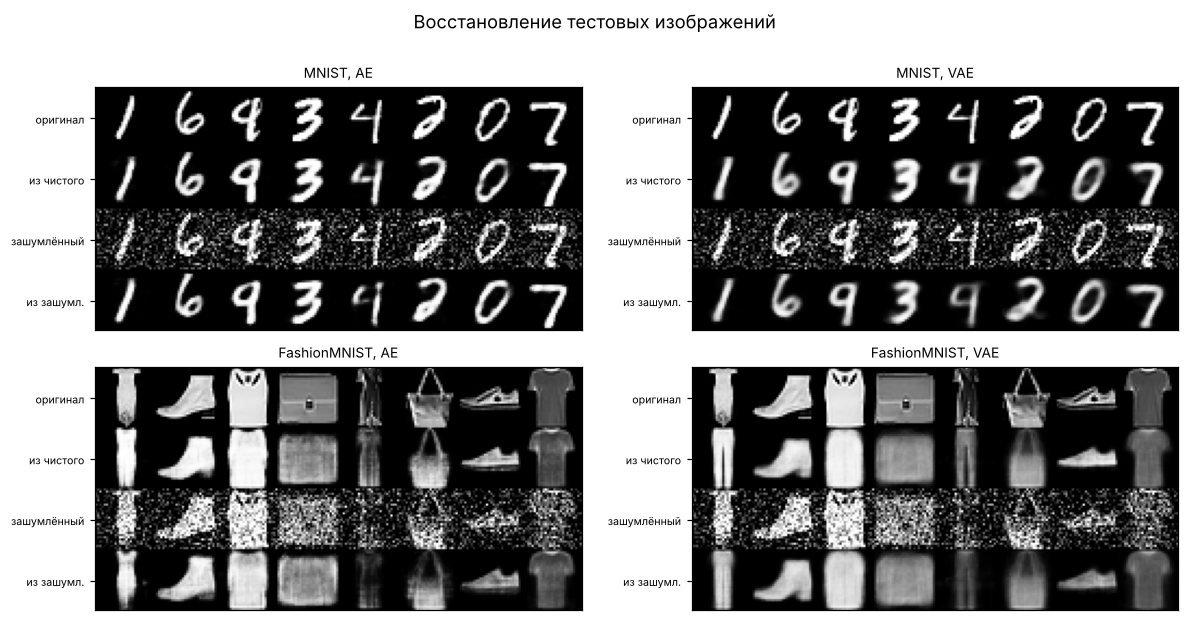

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5.6))
for i, ds in enumerate(DATASETS):
    Xb = DATA[ds][2]
    Xb_n = noise_normal(Xb, BASE['level'], np.random.default_rng(1))
    for j, m in enumerate(MODELS):
        model = models_final[(ds, m)]
        rec_c, rec_n = reconstruct(model, Xb[:8]), reconstruct(model, Xb_n[:8])
        # строки: оригинал, восстановленный по нему, зашумлённый, восстановленный по зашумлённому
        canvas = np.vstack([np.hstack(list(r)) for r in [Xb[:8], rec_c, Xb_n[:8], rec_n]])
        axes[i, j].imshow(canvas, cmap='gray')
        axes[i, j].set_title(f'{ds}, {m}', fontsize=9)
        axes[i, j].set_yticks([14, 42, 70, 98])
        axes[i, j].set_yticklabels(['оригинал', 'из чистого', 'зашумлённый', 'из зашумл.'], fontsize=7)
        axes[i, j].set_xticks([])
fig.suptitle('Восстановление тестовых изображений', y=1.0)
plt.tight_layout()
plt.show()

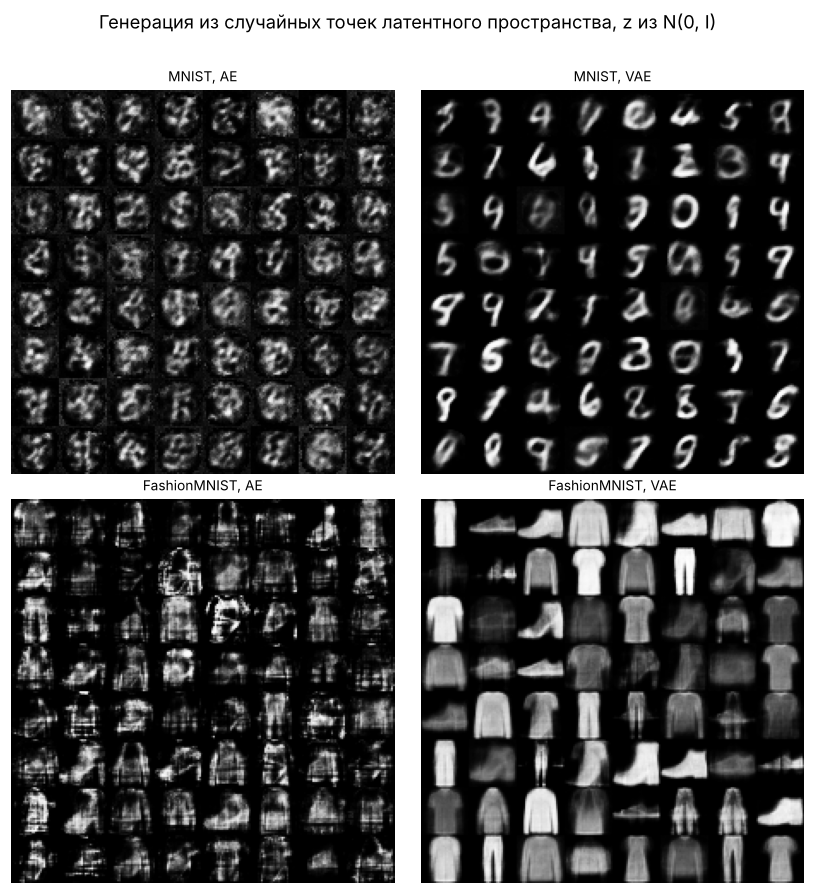

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(7.6, 8))
for i, ds in enumerate(DATASETS):
    for j, m in enumerate(MODELS):
        model = models_final[(ds, m)]
        model.eval()
        with torch.no_grad():
            imgs = model.sample(64).cpu().numpy().reshape(-1, 28, 28)
        # 64 изображения выкладываются в таблицу 8 на 8
        canvas = np.vstack([np.hstack([imgs[r * 8 + c] for c in range(8)])
                            for r in range(8)])
        axes[i, j].imshow(canvas, cmap='gray')
        axes[i, j].set_title(f'{ds}, {m}', fontsize=9)
        axes[i, j].axis('off')
fig.suptitle('Генерация из случайных точек латентного пространства, z из N(0, I)', y=1.01)
plt.tight_layout()
plt.show()

стандартное отклонение координат кода, среднее по координатам (у N(0, 1) было бы 1.000):
  MNIST        AE  1.940
  MNIST        VAE 1.111
  FashionMNIST AE  1.298
  FashionMNIST VAE 1.221


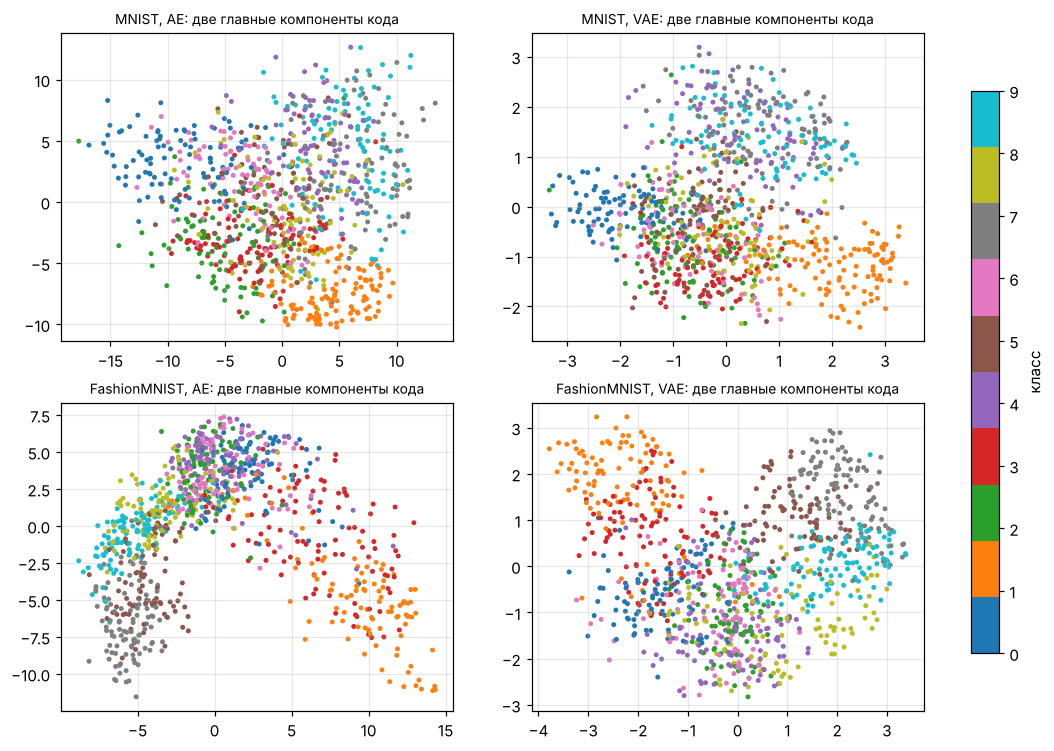

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
print('стандартное отклонение координат кода, среднее по координатам (у N(0, 1) было бы 1.000):')
for i, ds in enumerate(DATASETS):
    Xb, yb = DATA[ds][2], DATA[ds][3]
    x = torch.tensor(Xb.reshape(len(Xb), -1)).to(DEVICE)
    for j, m in enumerate(MODELS):
        model = models_final[(ds, m)]
        model.eval()
        with torch.no_grad():
            if m == 'AE':
                z = model.encoder(x).cpu().numpy()
                z_spread = z
            else:
                h = model.encoder(x)
                mu, logvar = model.mu(h), model.logvar(h)
                z = mu.cpu().numpy()
                # код с шумом, как при обучении: именно его разброс сравнивается с N(0, 1)
                z_spread = (mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)).cpu().numpy()
        print(f'  {ds:12s} {m:3s} {z_spread.std(0).mean():.3f}')
        p = PCA(2).fit_transform(z)  # латент сжимается до двух координат ради картинки
        sc = axes[i, j].scatter(p[:, 0], p[:, 1], c=yb, cmap='tab10', s=5)
        axes[i, j].set_title(f'{ds}, {m}: две главные компоненты кода', fontsize=9)
        axes[i, j].grid(alpha=0.3)
plt.colorbar(sc, ax=axes, label='класс', fraction=0.03)
plt.show()